<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/percival_dual_encoder_prototype.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Environment Setup & Core Imports]
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Percival VLM Contrastive Environment Initialized on: {device}")

Percival VLM Contrastive Environment Initialized on: cuda


In [2]:
# [CELL 2 - Symmetric Dual-Encoder Definition]

class SimulatedCTEncoder(nn.Module):
    """Simulates a 3D CT volume encoder projecting volumetric scans into latent space."""
    def __init__(self, embedding_dim: int = 128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, embedding_dim)
        )
    def forward(self, x):
        return F.normalize(self.net(x), p=2, dim=-1)

class SimulatedTextEncoder(nn.Module):
    """Simulates a radiology report text encoder projecting text tokens into latent space."""
    def __init__(self, embedding_dim: int = 128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(300, 256),
            nn.ReLU(),
            nn.Linear(256, embedding_dim)
        )
    def forward(self, x):
        return F.normalize(self.net(x), p=2, dim=-1)

print("Dual-Encoder Modules Defined Successfully.")

Dual-Encoder Modules Defined Successfully.


In [3]:
# [CELL 3 - Symmetric Contrastive Loss Function]

class SymmetricContrastiveLoss(nn.Module):
    """
    Computes bidirectional InfoNCE contrastive loss
    for image-text alignment in multimodal contrastive pretraining.
    """
    def __init__(self, temperature: float = 0.07):
        super().__init__()
        self.temperature = temperature
        self.logit_scale = nn.Parameter(torch.ones([]) * np.log(1 / temperature))

    def forward(self, image_features: torch.Tensor, text_features: torch.Tensor) -> torch.Tensor:
        # Normalized features
        image_features = F.normalize(image_features, dim=-1)
        text_features = F.normalize(text_features, dim=-1)

        # Cosine similarity matrix
        logit_scale = self.logit_scale.exp()
        logits_per_image = logit_scale * image_features @ text_features.t()
        logits_per_text = logits_per_image.t()

        batch_size = image_features.shape[0]
        labels = torch.arange(batch_size, device=image_features.device)

        loss_image = F.cross_entropy(logits_per_image, labels)
        loss_text = F.cross_entropy(logits_per_text, labels)

        return (loss_image + loss_text) / 2.0

contrastive_loss_fn = SymmetricContrastiveLoss()
print("Symmetric Contrastive Loss Initialized.")

Symmetric Contrastive Loss Initialized.


In [4]:
# [CELL 4 - Mock Pretraining Training Loop Step]

vision_encoder = SimulatedCTEncoder(embedding_dim=128).to(device)
text_encoder = SimulatedTextEncoder(embedding_dim=128).to(device)
optimizer = torch.optim.Adam(list(vision_encoder.parameters()) + list(text_encoder.parameters()), lr=1e-3)

# Generate batch of mock CT representations and report embeddings
batch_size = 32
mock_ct_volumes = torch.randn(batch_size, 512).to(device)
mock_reports = torch.randn(batch_size, 300).to(device)

vision_encoder.train()
text_encoder.train()

optimizer.zero_grad()
img_feats = vision_encoder(mock_ct_volumes)
txt_feats = text_encoder(mock_reports)

loss = contrastive_loss_fn(img_feats, txt_feats)
loss.backward()
optimizer.step()

print(f"Pretraining Step Successful -> Symmetric Contrastive Loss: {loss.item():.4f}")

Pretraining Step Successful -> Symmetric Contrastive Loss: 3.8467


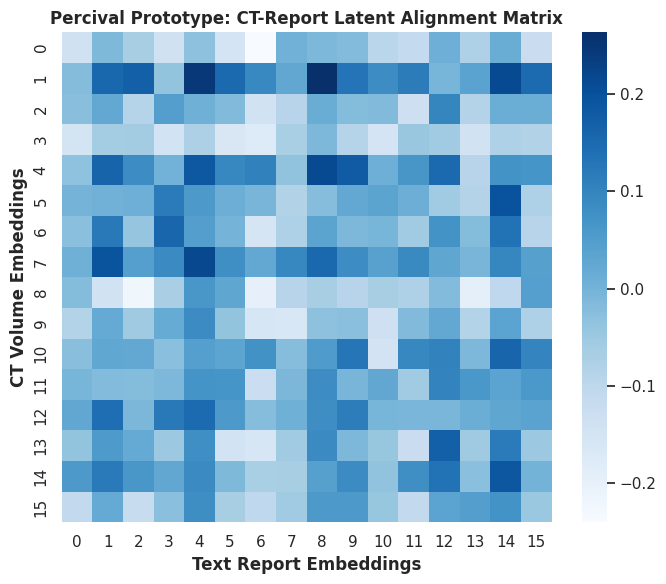

Contrastive alignment plot saved successfully as percival_contrastive_alignment.png.


In [5]:
# [CELL 5 - Visualization of Image-Text Similarity Matrix]

vision_encoder.eval()
text_encoder.eval()
with torch.no_grad():
    val_img = vision_encoder(torch.randn(16, 512).to(device))
    val_txt = text_encoder(torch.randn(16, 300).to(device))
    similarity_matrix = (val_img @ val_txt.t()).cpu().numpy()

plt.figure(figsize=(7, 6))
sns.heatmap(similarity_matrix, cmap="Blues", cbar=True)
plt.title("Percival Prototype: CT-Report Latent Alignment Matrix", fontweight='bold')
plt.xlabel("Text Report Embeddings", fontweight='bold')
plt.ylabel("CT Volume Embeddings", fontweight='bold')
plt.tight_layout()
plt.savefig("percival_contrastive_alignment.png", dpi=300)
plt.show()

print("Contrastive alignment plot saved successfully as percival_contrastive_alignment.png.")